# Taller · De los datos a un dashboard publicado

**Programación ADMI 1301 · Universidad de los Andes**  
**Caso:** cadena de papelerías, ventas de 2025.

Este notebook reproducible puede trabajarse en **GitHub Codespaces con Jupyter** y publicarse en un repositorio público de GitHub. El archivo `ventas_papelerias_2025.csv` debe estar en la misma carpeta.

> **Uso académico:** la guía indica que el estudiante debe escribir por sí mismo el código de las partes A y B; la IA se usa solo en la parte C. La solución incluida aquí sirve como **referencia comentada** para estudiarla y verificar los resultados. Si vas a entregar este trabajo, desarrolla tú los ejercicios correspondientes y describe con veracidad tus propias iteraciones con IA. La guía también menciona un notebook original con verificaciones, que no se adjuntó a esta conversación.

## Sección 0 · Cargar los datos

El CSV se lee desde el repositorio. Así no depende del botón de subida de Colab y funciona en Codespaces, Jupyter local o Colab cuando CSV y notebook están en la misma carpeta.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

RUTA_CSV = Path("ventas_papelerias_2025.csv")
if not RUTA_CSV.exists():
    raise FileNotFoundError("Sube ventas_papelerias_2025.csv a la misma carpeta que este notebook.")

df = pd.read_csv(RUTA_CSV)
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month
print(f"Datos cargados: {len(df):,} filas y {len(df.columns)} columnas (incluyendo 'mes').")
assert len(df) == 2000, "La guía espera 2000 registros."
assert df.isna().sum().sum() == 0, "Se encontraron datos faltantes."

Datos cargados: 2,000 filas y 14 columnas (incluyendo 'mes').


## Conoce tus datos

In [2]:
display(df.head())
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes.to_string())
for col in ["ciudad", "canal", "segmento", "categoria"]:
    print(f"\n{col}:", sorted(df[col].unique()))

,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


Dimensiones: (2000, 14)

Tipos de datos:
id_venta                   object
fecha              datetime64[ns]
ciudad                     object
canal                      object
segmento                   object
vendedor                   object
producto                   object
categoria                  object
metodo_pago                object
cantidad                    int64
precio_unitario             int64
descuento                 float64
total                       int64
mes                         int32

ciudad: ['Barranquilla', 'Bogotá', 'Bucaramanga', 'Cali', 'Medellín']

canal: ['Online', 'Telefónico', 'Tienda']

segmento: ['Corporativo', 'Mayorista', 'Minorista']

categoria: ['Arte', 'Corrección', 'Escritura', 'Organización', 'Papel']


# Parte A · Seis gráficos

### Ejercicio 1 · Top 5 de productos por ingresos

Agrupar por producto, sumar ingresos, ordenar de mayor a menor y seleccionar cinco productos. El más importante debe ser **Cuaderno**.

producto
Cuaderno          20712345
Block de notas    14292347
Resma carta       13133570
Marcador          10020786
Colores x12        9419625


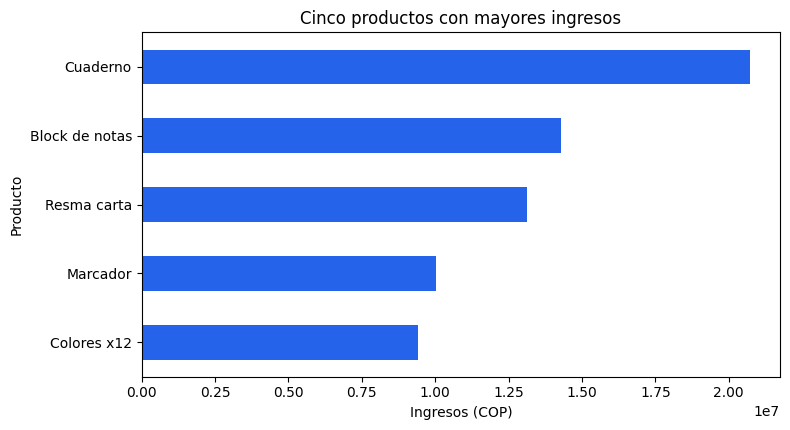

In [3]:
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
assert len(top_productos) == 5
assert top_productos.index[0] == "Cuaderno"
print(top_productos.to_string())
ax = top_productos.sort_values().plot.barh(figsize=(8, 4.4), color="#2563eb")
ax.set(title="Cinco productos con mayores ingresos", xlabel="Ingresos (COP)", ylabel="Producto")
plt.tight_layout()
plt.show()

### Ejercicio 2 · Ingresos mensuales de Bogotá y Medellín

Filtrar las dos ciudades y crear una tabla dinámica de 12 meses por 2 ciudades.

ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


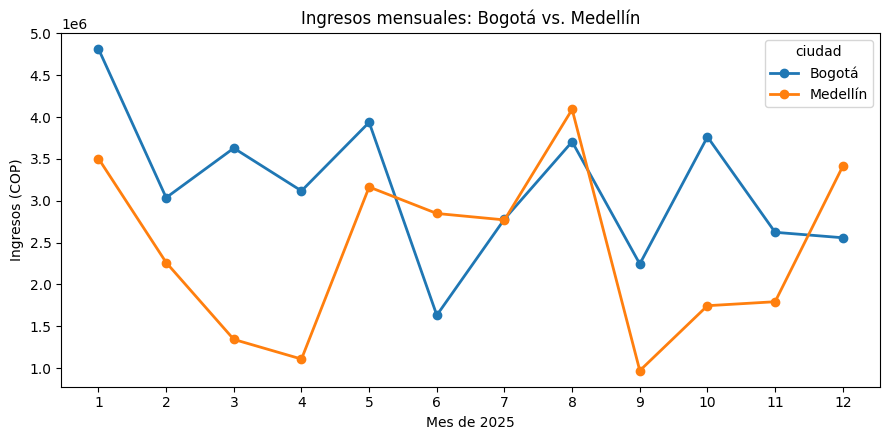

In [4]:
filtrado_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = filtrado_ciudades.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_mes_ciudad = ing_mes_ciudad.reindex(index=range(1, 13), fill_value=0)
assert ing_mes_ciudad.shape == (12, 2)
display(ing_mes_ciudad)
ax = ing_mes_ciudad.plot.line(figsize=(9, 4.5), marker="o", linewidth=2)
ax.set(title="Ingresos mensuales: Bogotá vs. Medellín", xlabel="Mes de 2025", ylabel="Ingresos (COP)", xticks=range(1, 13))
plt.tight_layout()
plt.show()

### Ejercicio 3 · Participación de ingresos por canal

La proporción del canal **Telefónico** debe superar 50 %.

canal
Telefónico    51.78
Tienda        28.93
Online        19.29


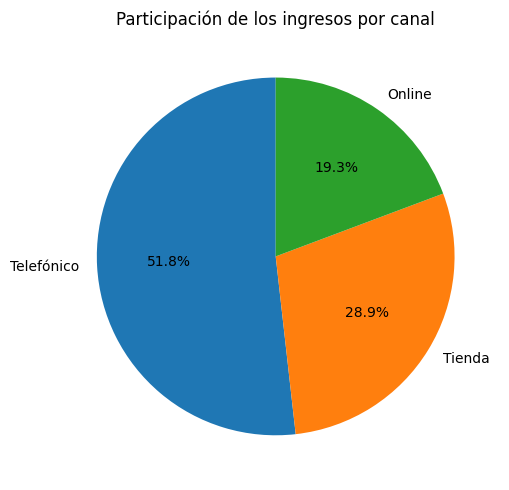

In [5]:
ing_canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
assert ing_canal["Telefónico"] / ing_canal.sum() > 0.5
print((ing_canal / ing_canal.sum() * 100).round(2).to_string())
ax = ing_canal.plot.pie(figsize=(6.5, 5), autopct="%1.1f%%", ylabel="", startangle=90)
ax.set_title("Participación de los ingresos por canal")
plt.tight_layout()
plt.show()

### Ejercicio 4 · Categoría de producto por segmento

Crosstab de conteos normalizados por fila. Cada segmento debe sumar 100 %.

categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.8,5.4,30.2,23.3,38.2
Mayorista,5.6,12.2,54.0,5.6,22.5
Minorista,12.1,12.8,55.8,4.3,15.2


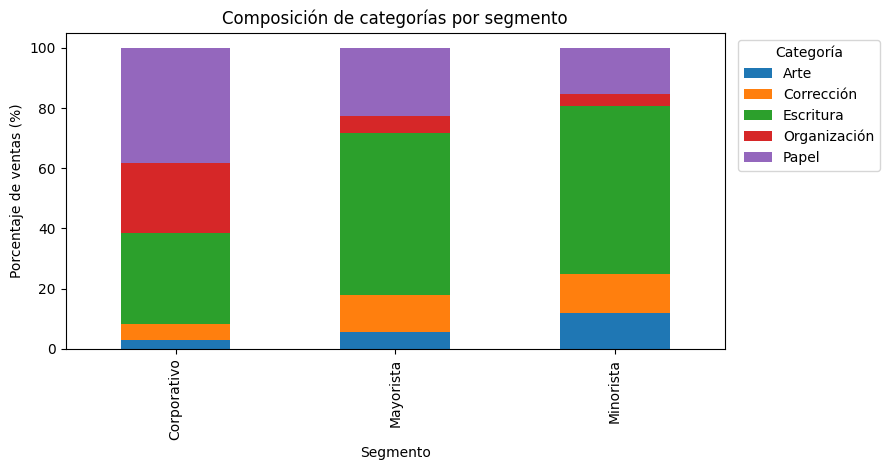

In [6]:
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
assert tabla_seg_cat.shape == (3, 5)
assert np.allclose(tabla_seg_cat.sum(axis=1).values, 100)
display(tabla_seg_cat.round(1))
ax = tabla_seg_cat.plot.bar(stacked=True, figsize=(9, 4.8))
ax.set(title="Composición de categorías por segmento", xlabel="Segmento", ylabel="Porcentaje de ventas (%)")
ax.legend(title="Categoría", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Ejercicio 5 · Productividad de los 12 vendedores

Cada punto representa un vendedor. X: cantidad de ventas. Y: ticket promedio. Color: ciudad.

,vendedor,ciudad,n_ventas,ticket_prom
6,Laura Gómez,Bogotá,312,58564.371795
5,Julián Cortés,Cali,215,56389.920930
10,Sofía Mejía,Medellín,215,53688.744186
1,Camilo Pardo,Bogotá,210,54276.595238
0,Andrés Rojas,Medellín,192,60729.104167
7,Mateo Peña,Barranquilla,165,60888.484848
8,Paula Vargas,Cali,136,76343.213235
2,Daniela Ríos,Bogotá,130,62903.423077
11,Valeria Ortiz,Barranquilla,122,49982.418033
4,Isabela Mora,Bucaramanga,108,65873.037037


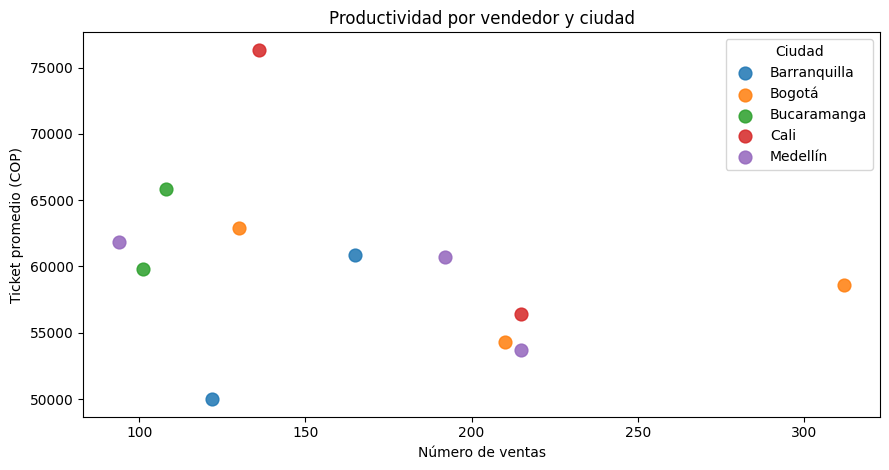

In [7]:
vend = (df.groupby(["vendedor", "ciudad"])
        .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
        .reset_index())
assert len(vend) == 12
assert vend["n_ventas"].sum() == 2000
display(vend.sort_values("n_ventas", ascending=False))
fig, ax = plt.subplots(figsize=(9, 4.8))
for ciudad, grupo in vend.groupby("ciudad"):
    ax.scatter(grupo["n_ventas"], grupo["ticket_prom"], s=85, label=ciudad, alpha=.86)
ax.set(title="Productividad por vendedor y ciudad", xlabel="Número de ventas", ylabel="Ticket promedio (COP)")
ax.legend(title="Ciudad")
plt.tight_layout()
plt.show()

### Ejercicio 6 · Valor de ventas en el segundo semestre

Filtrar de julio a diciembre, 1.050 ventas. Boxplot por segmento sin valores atípicos.

Ventas de julio a diciembre: 1050


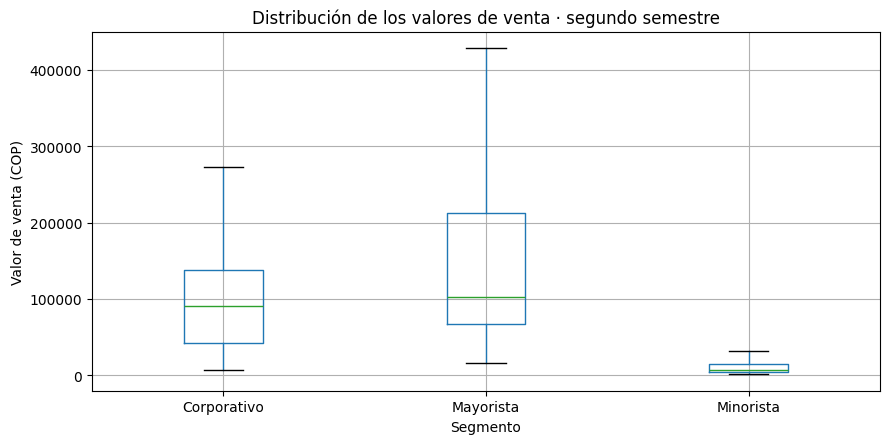

In [8]:
sem2 = df[df["mes"] >= 7].copy()
assert len(sem2) == 1050
print("Ventas de julio a diciembre:", len(sem2))
ax = sem2.boxplot(column="total", by="segmento", showfliers=False, figsize=(9, 4.7))
ax.set(title="Distribución de los valores de venta · segundo semestre", xlabel="Segmento", ylabel="Valor de venta (COP)")
plt.suptitle("")
plt.tight_layout()
plt.show()

# Parte B · Una sola figura con 2 × 3 subplots

El siguiente código genera `figura_base.py`, tal como pide la guía. Después se ejecuta para obtener un dashboard con seis subplots.

In [9]:
%%writefile figura_base.py
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0], color="#2563eb", title="Top 5 productos")
axs[0, 0].set(xlabel="Ingresos (COP)", ylabel="Producto")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Bogotá vs. Medellín")
axs[0, 1].set(xlabel="Mes", ylabel="Ingresos (COP)", xticks=range(1, 13))

ing_canal.plot.pie(ax=axs[0, 2], autopct="%1.1f%%", startangle=90, ylabel="", title="Ingresos por canal")

tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, title="Categoría por segmento")
axs[1, 0].set(xlabel="Segmento", ylabel="Porcentaje (%)")
axs[1, 0].legend(fontsize=8, title="Categoría")

for ciudad, grupo in vend.groupby("ciudad"):
    axs[1, 1].scatter(grupo["n_ventas"], grupo["ticket_prom"], s=75, label=ciudad)
axs[1, 1].set(title="Productividad por vendedor", xlabel="N.º ventas", ylabel="Ticket prom. (COP)")
axs[1, 1].legend(fontsize=8, title="Ciudad")

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set(title="Ticket por segmento · semestre 2", xlabel="Segmento", ylabel="Venta (COP)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18, y=1.02)
plt.tight_layout()
assert len(fig.axes) == 6, "La figura debe tener seis ejes."
plt.show()

Overwriting figura_base.py


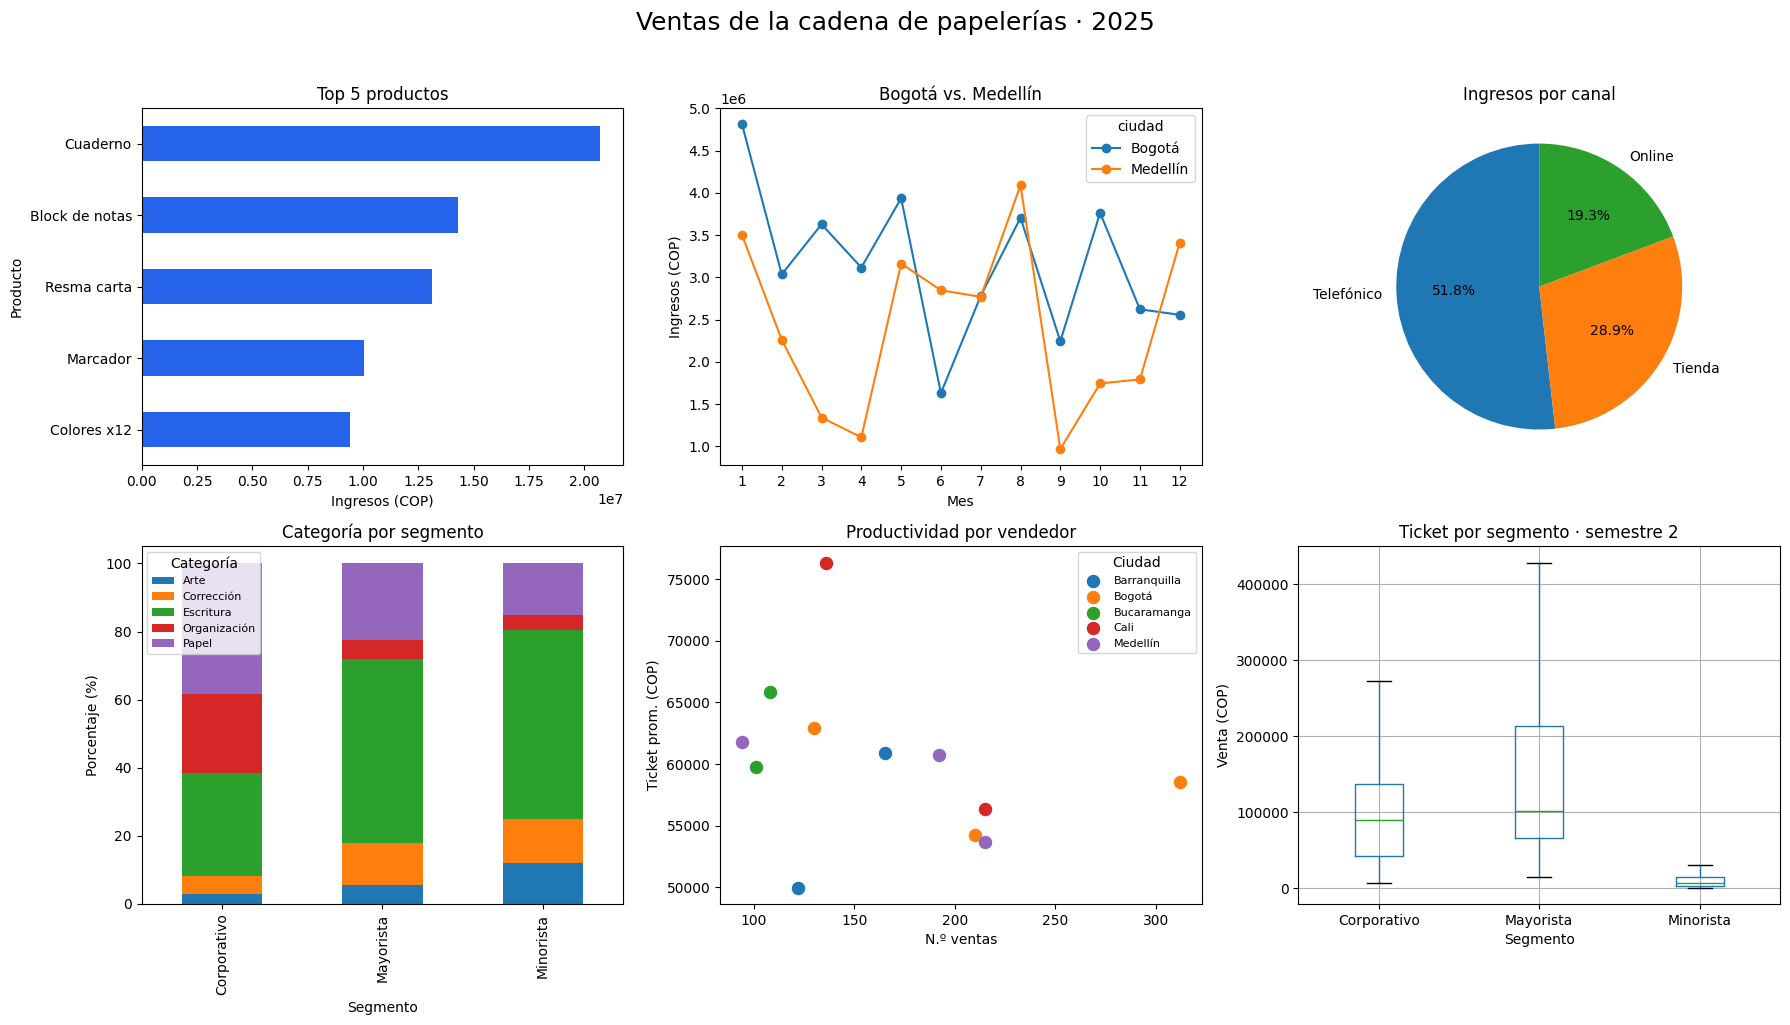

In [10]:
%run -i figura_base.py

# Parte C · Mejora con prompts

La guía solicita una primera versión y una iteración con **al menos dos cambios concretos**. A continuación hay dos ejemplos de prompts completos, y dos variantes visuales que respetan los datos de las partes A y B. Si tienes tus propios prompts o recibes código de Gemini, sustitúyelos para documentar tu proceso real.

### Ejercicio 8 · Prompt de estilo v1

In [11]:
prompt_v1 = """PÚBLICO Y OBJETIVO: Un dashboard para la junta gerencial de la cadena de papelerías. Debe permitir comparar ingresos, canales, segmentos y vendedores sin modificar las seis métricas originales.
PALETA Y TIPOGRAFÍA: Fondo gris claro (#f3f6fb), paneles blancos. Azul marino para ingresos, azul para Bogotá, naranja para Medellín; Cali verde, Barranquilla dorado y Bucaramanga violeta. Fuente sans-serif y títulos de al menos 11 puntos.
TÍTULOS: Seis títulos interpretativos que incluyan conclusiones comprobables a partir de las tablas; título general con 2025.
EJES Y NÚMEROS: Formatear ingresos en millones de pesos colombianos (COP M), eje de meses 1 a 12, porcentajes claros. Mostrar porcentajes con un decimal.
LIMPIEZA VISUAL: Quitar bordes superiores y derechos, suavizar cuadrículas, conservar leyendas legibles; no cambiar el tipo de análisis ni los seis gráficos.
REGLAS: Usar exclusivamente top_productos, ing_mes_ciudad, ing_canal, tabla_seg_cat, vend y sem2. Debe existir fig, axs = plt.subplots(2,3). No modificar tablas ni filtrar registros adicionales. Conservar los seis gráficos y verificar cada cifra."""
print(prompt_v1)

PÚBLICO Y OBJETIVO: Un dashboard para la junta gerencial de la cadena de papelerías. Debe permitir comparar ingresos, canales, segmentos y vendedores sin modificar las seis métricas originales.
PALETA Y TIPOGRAFÍA: Fondo gris claro (#f3f6fb), paneles blancos. Azul marino para ingresos, azul para Bogotá, naranja para Medellín; Cali verde, Barranquilla dorado y Bucaramanga violeta. Fuente sans-serif y títulos de al menos 11 puntos.
TÍTULOS: Seis títulos interpretativos que incluyan conclusiones comprobables a partir de las tablas; título general con 2025.
EJES Y NÚMEROS: Formatear ingresos en millones de pesos colombianos (COP M), eje de meses 1 a 12, porcentajes claros. Mostrar porcentajes con un decimal.
LIMPIEZA VISUAL: Quitar bordes superiores y derechos, suavizar cuadrículas, conservar leyendas legibles; no cambiar el tipo de análisis ni los seis gráficos.
REGLAS: Usar exclusivamente top_productos, ing_mes_ciudad, ing_canal, tabla_seg_cat, vend y sem2. Debe existir fig, axs = plt.su

### Código de la versión v1

En el taller original, esta celda se llenaría pegando el código de la IA sin delimitadores de Markdown. Aquí se incluye una versión de ejemplo ejecutable.

In [12]:
%%writefile figura_v1.py
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

PALETA = {"Bogotá": "#2563eb", "Medellín": "#e8792f", "Cali": "#16a34a", "Barranquilla": "#eab308", "Bucaramanga": "#7c3aed"}
MILLONES = FuncFormatter(lambda x, pos: f"$ {x / 1e6:.0f} M")
MILES = FuncFormatter(lambda x, pos: f"$ {x / 1e3:,.0f} mil")

fig, axs = plt.subplots(2, 3, figsize=(19, 10.5), facecolor="#f3f6fb")
for ax in axs.flat:
    ax.set_facecolor("white")
    ax.grid(axis="y", alpha=.12)
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)

ax = axs[0, 0]
top_productos.sort_values().plot.barh(ax=ax, color="#234a75", legend=False)
ax.set(title="Cuaderno lidera los ingresos", ylabel="", xlabel="Ingresos")
ax.xaxis.set_major_formatter(MILLONES)

ax = axs[0, 1]
for ciudad in ["Bogotá", "Medellín"]:
    ax.plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad], marker="o", lw=2, color=PALETA[ciudad], label=ciudad)
ax.set(title="Bogotá supera a Medellín en el año", xlabel="Mes", ylabel="Ingresos", xticks=list(range(1, 13)))
ax.yaxis.set_major_formatter(MILLONES)
ax.legend(frameon=False, fontsize=9)

ax = axs[0, 2]
ax.grid(False)
ing_canal.plot.pie(ax=ax, autopct="%1.1f%%", ylabel="", startangle=90, colors=["#234a75", "#5ea1d8", "#b8c5d6"])
ax.set_title("Telefónico concentra más de la mitad")

ax = axs[1, 0]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, color=["#b5cee7", "#5c9ac5", "#234a75", "#e5a362", "#73b7a9"])
ax.set(title="Cada segmento compra categorías distintas", xlabel="", ylabel="Participación (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Categoría", fontsize=8, title_fontsize=8, frameon=False)

ax = axs[1, 1]
for ciudad, grupo in vend.groupby("ciudad"):
    ax.scatter(grupo.n_ventas, grupo.ticket_prom, s=90, alpha=.85, color=PALETA[ciudad], label=ciudad)
ax.set(title="Vendedores: frecuencia vs. ticket", xlabel="Número de ventas", ylabel="Ticket promedio")
ax.yaxis.set_major_formatter(MILES)
ax.legend(fontsize=8, title="Ciudad", title_fontsize=8, frameon=False)

ax = axs[1, 2]
sem2.boxplot(column="total", by="segmento", ax=ax, showfliers=False, boxprops={"color": "#234a75"}, medianprops={"color": "#e8792f", "linewidth": 2})
ax.set(title="Mayoristas tienen tickets más altos", xlabel="", ylabel="Valor de venta")
ax.yaxis.set_major_formatter(MILES)

fig.suptitle("PAPELERÍAS 2025  |  Dashboard gerencial", fontsize=19, fontweight="bold", color="#183a5c", y=.99)
fig.text(.5, .945, "2.000 ventas  •  5 ciudades  •  12 vendedores", ha="center", color="#546478")
fig.subplots_adjust(left=.06, right=.97, top=.89, bottom=.08, wspace=.36, hspace=.40)
assert len(fig.axes) == 6

Overwriting figura_v1.py


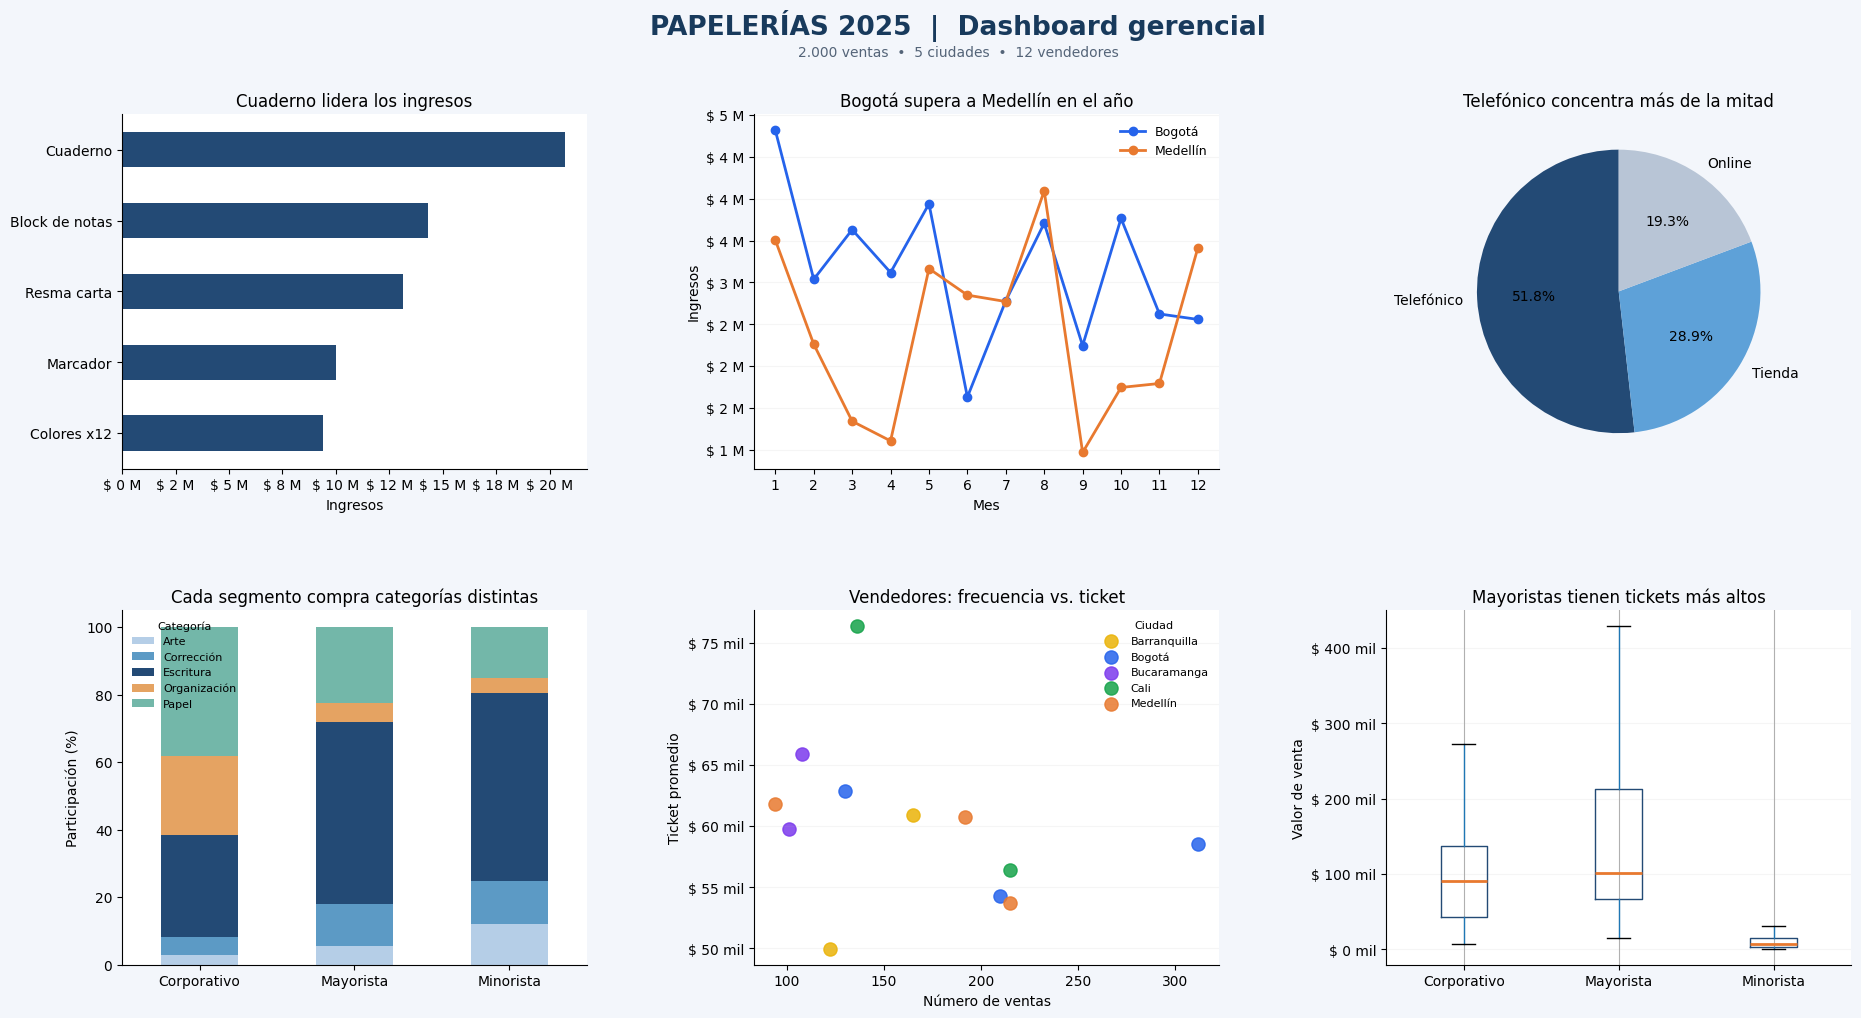

In [13]:
def mostrar(nombre):
    ruta = Path(f"figura_{nombre}.py")
    if not ruta.exists():
        raise FileNotFoundError(f"No se encuentra {ruta}")
    codigo = ruta.read_text(encoding="utf-8")
    exec(compile(codigo, str(ruta), "exec"), globals())
    plt.show()

mostrar("v1")

### Ejercicio 9 · Prompt de iteración v2

Esta segunda versión propone cambios observables sobre v1: gráfico de dona, fuentes más grandes, marcador de máximo mensual y tarjetas de indicadores.

In [14]:
prompt_v2 = prompt_v1 + """
AJUSTES SOLICITADOS DESPUÉS DE REVISAR V1:
1. Convertir el gráfico pie en una dona manteniendo exactamente los mismos tres porcentajes por canal.
2. Agrandar títulos y etiquetas para proyectar en una junta, y evitar que se superpongan las leyendas.
3. Resaltar con una anotación el pico mensual de Bogotá en la gráfica de líneas sin cambiar los 12 valores.
4. Añadir encima del tablero una banda de KPIs con ingreso total, participación del canal Telefónico y número de transacciones; sin agregar un séptimo subplot.
5. Mantener márgenes limpios, formato COP millones y la cuadrícula de 2 × 3.
"""
print(prompt_v2)

PÚBLICO Y OBJETIVO: Un dashboard para la junta gerencial de la cadena de papelerías. Debe permitir comparar ingresos, canales, segmentos y vendedores sin modificar las seis métricas originales.
PALETA Y TIPOGRAFÍA: Fondo gris claro (#f3f6fb), paneles blancos. Azul marino para ingresos, azul para Bogotá, naranja para Medellín; Cali verde, Barranquilla dorado y Bucaramanga violeta. Fuente sans-serif y títulos de al menos 11 puntos.
TÍTULOS: Seis títulos interpretativos que incluyan conclusiones comprobables a partir de las tablas; título general con 2025.
EJES Y NÚMEROS: Formatear ingresos en millones de pesos colombianos (COP M), eje de meses 1 a 12, porcentajes claros. Mostrar porcentajes con un decimal.
LIMPIEZA VISUAL: Quitar bordes superiores y derechos, suavizar cuadrículas, conservar leyendas legibles; no cambiar el tipo de análisis ni los seis gráficos.
REGLAS: Usar exclusivamente top_productos, ing_mes_ciudad, ing_canal, tabla_seg_cat, vend y sem2. Debe existir fig, axs = plt.su

In [15]:
%%writefile figura_v2.py
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

AZUL = "#103d68"
TONO = "#2b7ec1"
NARANJA = "#ef8b45"
PALETA = {"Bogotá": TONO, "Medellín": NARANJA, "Cali": "#37a477", "Barranquilla": "#dbb03f", "Bucaramanga": "#9068c7"}
MILLONES = FuncFormatter(lambda x, pos: f"$ {x / 1e6:.0f} M")
MILES = FuncFormatter(lambda x, pos: f"$ {x / 1e3:,.0f} mil")

fig, axs = plt.subplots(2, 3, figsize=(20, 11.7), facecolor="#f5f7fb")
for ax in axs.flat:
    ax.set_facecolor("white")
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#dce5ee", alpha=.55, lw=.7)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.tick_params(labelsize=9, colors="#48576b", length=0, pad=5)
    ax.title.set_fontsize(12.5)
    ax.title.set_weight("bold")
    ax.title.set_color(AZUL)

# Panel 1 · top 5 de ingresos
ax = axs[0, 0]
vals = top_productos.sort_values()
vals.plot.barh(ax=ax, color=TONO, legend=False, width=.62)
ax.set(title="Cuaderno es el producto #1", xlabel="Ingresos (COP)", ylabel="")
ax.xaxis.set_major_formatter(MILLONES)
for i, v in enumerate(vals.to_numpy()):
    ax.annotate(f"{v / 1e6:.1f} M", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8.5, color=AZUL)
ax.set_xlim(0, vals.max() * 1.20)

# Panel 2 · evolución mensual
ax = axs[0, 1]
for ciudad in ["Bogotá", "Medellín"]:
    ax.plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad], lw=2.6, marker="o", ms=5, label=ciudad, color=PALETA[ciudad])
mes_pico = int(ing_mes_ciudad["Bogotá"].idxmax())
valor_pico = float(ing_mes_ciudad.loc[mes_pico, "Bogotá"])
ax.annotate(f"Pico Bogotá: {valor_pico/1e6:.1f} M", xy=(mes_pico, valor_pico), xytext=(mes_pico, valor_pico*1.19),
            arrowprops={"arrowstyle": "->", "color": TONO, "lw": 1}, fontsize=8, ha="center", color=AZUL)
ax.set(title="Bogotá lidera el acumulado anual", xlabel="Mes de 2025", ylabel="Ingresos (COP)", xticks=list(range(1, 13)))
ax.yaxis.set_major_formatter(MILLONES)
ax.set_ylim(0, max(ing_mes_ciudad.max()) * 1.45)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)

# Panel 3 · dona por canal
ax = axs[0, 2]
ax.grid(False)
ax.pie(ing_canal.values, labels=ing_canal.index, colors=[AZUL, "#6eabd2", "#a1bbc9"],
       startangle=90, autopct="%1.1f%%", pctdistance=.79,
       wedgeprops={"width": .43, "edgecolor": "white", "linewidth": 2},
       textprops={"fontsize": 9, "color": AZUL})
ax.text(0, 0, "Canales", ha="center", va="center", fontsize=10, weight="bold", color=AZUL)
ax.set_title("Telefónico: canal principal")

# Panel 4 · mezcla de categorías en %
ax = axs[1, 0]
tabla_seg_cat.plot.bar(ax=ax, stacked=True, width=.63,
                        color=["#b6cde2", "#7fb3d0", AZUL, "#edaa75", "#58b69c"], legend=False)
ax.set(title="Composición del carrito por segmento", xlabel="", ylabel="Participación (%)", ylim=(0, 100))
ax.tick_params(axis="x", rotation=0)
ax.legend(tabla_seg_cat.columns, title="Categoría", loc="upper center", bbox_to_anchor=(.5, -.11),
          ncol=3, frameon=False, fontsize=8, title_fontsize=9)

# Panel 5 · dispersión por vendedor
ax = axs[1, 1]
for ciudad, grupo in vend.groupby("ciudad"):
    ax.scatter(grupo.n_ventas, grupo.ticket_prom, s=98, alpha=.9, color=PALETA[ciudad], label=ciudad,
               edgecolor="white", linewidth=.7)
ax.set(title="Ventas vs. ticket promedio por vendedor", xlabel="Número de ventas", ylabel="Ticket promedio (COP)")
ax.yaxis.set_major_formatter(MILES)
ax.legend(title="Ciudad", loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3, fontsize=8, title_fontsize=8, frameon=False)

# Panel 6 · segundo semestre, valores atípicos ocultos
ax = axs[1, 2]
sem2.boxplot(column="total", by="segmento", ax=ax, showfliers=False, patch_artist=True,
             boxprops={"facecolor": "#cce3f3", "color": TONO},
             medianprops={"color": NARANJA, "linewidth": 2.2},
             whiskerprops={"color": TONO}, capprops={"color": TONO})
ax.set(title="Tickets del segundo semestre por segmento", xlabel="", ylabel="Valor de venta (COP)")
ax.yaxis.set_major_formatter(MILES)

# Encabezado + banda de KPIs (sin alterar los 6 paneles)
ingresos = df["total"].sum()
participacion_telefonico = 100 * ing_canal["Telefónico"] / ingresos
fig.suptitle("PAPELERÍAS | RESULTADOS 2025", fontsize=21, fontweight="bold", color=AZUL, y=.979)
fig.text(.5, .924,
         f"INGRESOS  $ {ingresos / 1e6:,.1f} M COP      |      VENTAS  {len(df):,}      |      TELEFÓNICO  {participacion_telefonico:.1f} %",
         ha="center", fontsize=11.2, color=AZUL,
         bbox={"boxstyle": "round,pad=.65", "facecolor": "#e5eff8", "edgecolor": "none"})
fig.subplots_adjust(left=.055, right=.975, top=.82, bottom=.12, wspace=.34, hspace=.42)
assert len(fig.axes) == 6

Overwriting figura_v2.py


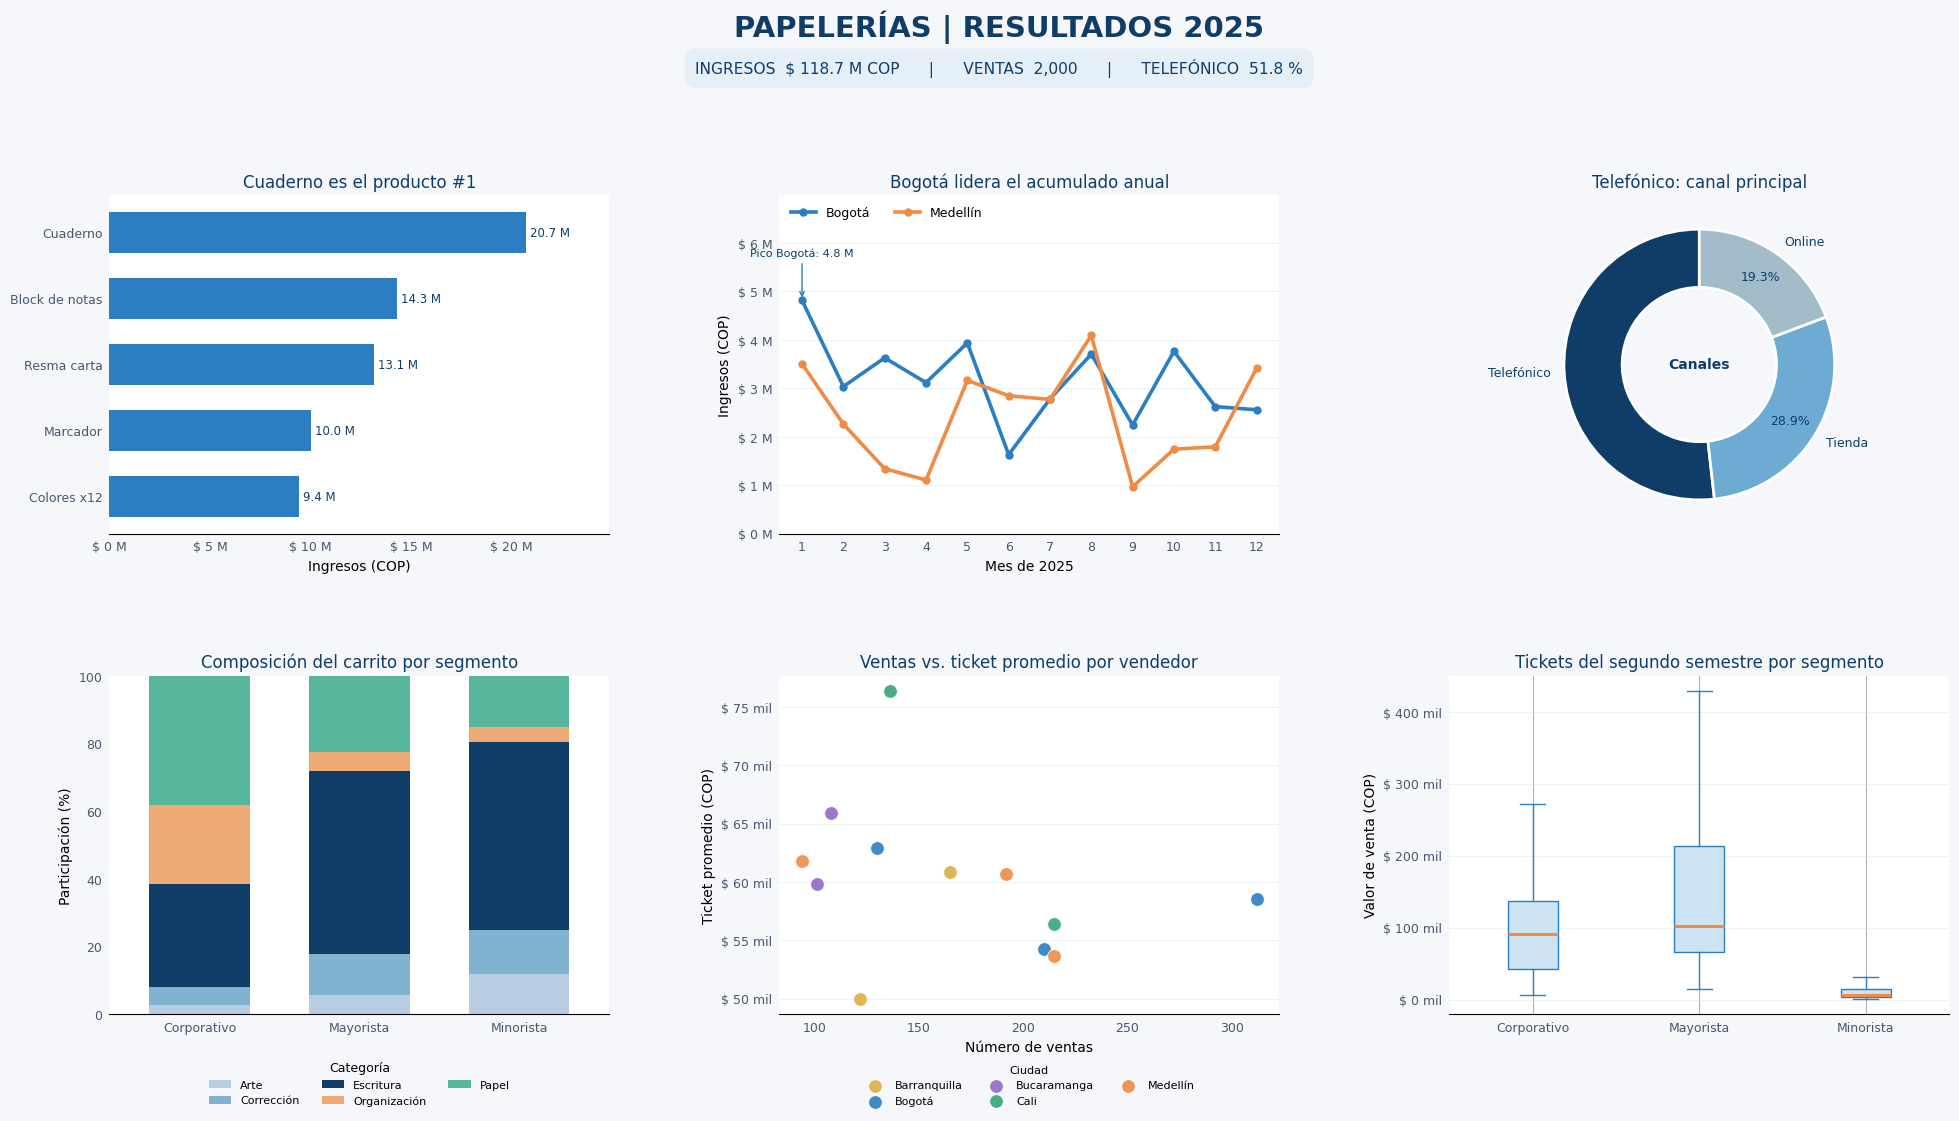

In [16]:
mostrar("v2")

# Parte D · Tu dashboard final y tres conclusiones

Elige aquí la versión que prefieras. La siguiente celda vuelve a dibujar la versión final: esta salida es la que debe verse al abrir el notebook en GitHub.

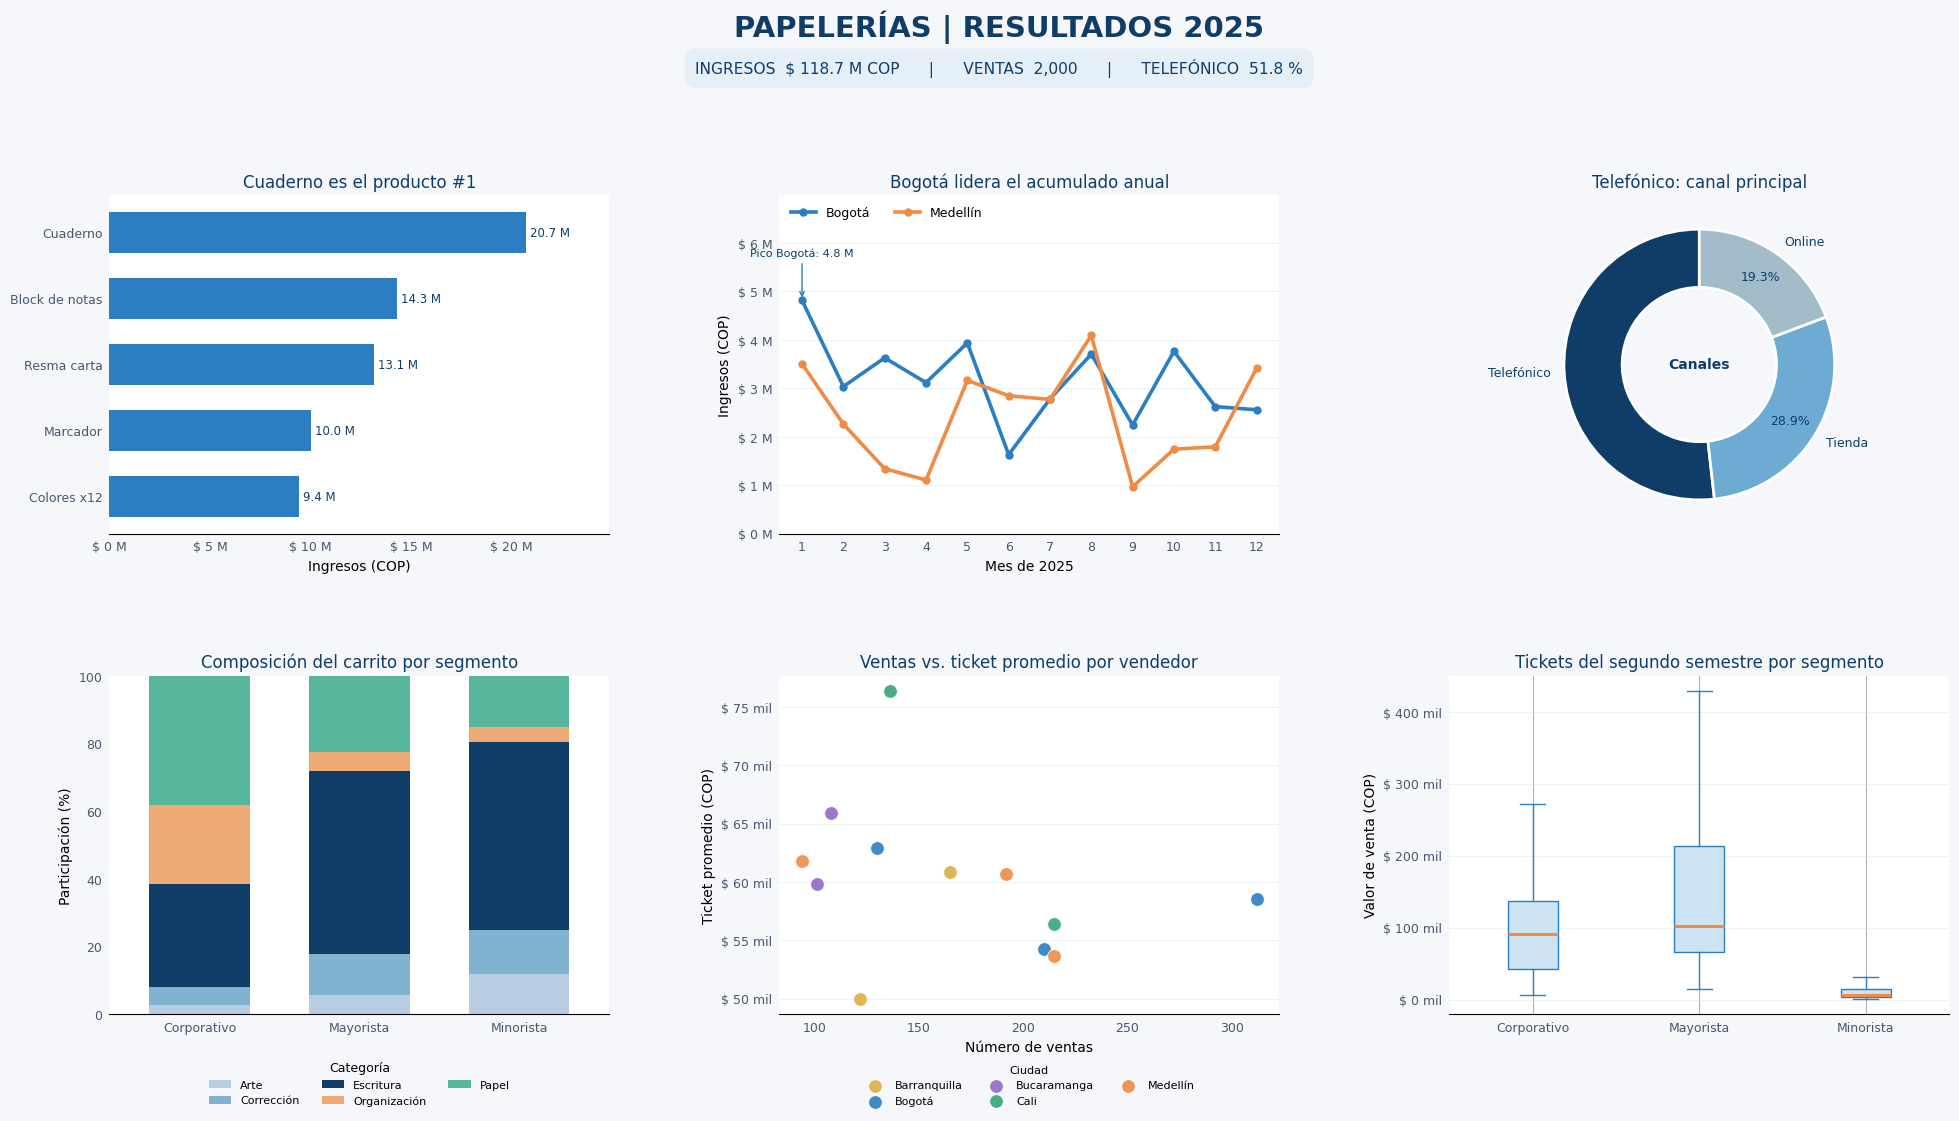


TRES HALLAZGOS COMPROBADOS
1. Cuaderno es el producto con más ingresos: $ 20,712,345 COP.
2. Telefónico representa 51.8 % de los ingresos anuales.
3. Bogotá genera 31.9 % de los ingresos de la cadena.


In [17]:
figura_elegida = "v2"  # Cambia a "v1" si la prefieres
assert figura_elegida in ("v1", "v2")
mostrar(figura_elegida)

participacion_telefonico = 100 * ing_canal["Telefónico"] / df["total"].sum()
participacion_bogota = 100 * df.loc[df["ciudad"] == "Bogotá", "total"].sum() / df["total"].sum()
print("\nTRES HALLAZGOS COMPROBADOS")
print(f"1. Cuaderno es el producto con más ingresos: $ {top_productos['Cuaderno']:,.0f} COP.")
print(f"2. Telefónico representa {participacion_telefonico:.1f} % de los ingresos anuales.")
print(f"3. Bogotá genera {participacion_bogota:.1f} % de los ingresos de la cadena.")

### Reflexión sobre la iteración con IA (completa según lo que realmente hiciste)

1. **Revisión de v1:** La visualización circular tenía bastante espacio ocupado por etiquetas; en el prompt v2 pedí convertirla en una dona, sin cambiar porcentajes.
2. **Legibilidad:** Las fuentes y leyendas de v1 podían ser pequeñas en una proyección; pedí títulos más grandes y que no hubiera superposiciones.
3. **Lectura gerencial:** En v2 pedí marcar el máximo de Bogotá y agregar una banda de indicadores sin alterar los seis gráficos ni sus datos.

> Verifica que estas tres observaciones describan tu proceso real antes de presentar la entrega. Si utilizaste Gemini u otra IA, consigna cuál y qué instrucciones precisas enviaste.

### Publicación en GitHub

1. Abre tu repositorio público (por ejemplo, `mi-dashboard-ventas`).
2. Sube **este notebook** y el archivo **`ventas_papelerias_2025.csv`** en la misma carpeta.
3. Para ejecutarlo desde GitHub, entra a **Code → Codespaces → Create codespace on main**; abre el `.ipynb` y selecciona un kernel Python con `pandas`, `matplotlib`, `numpy`, `ipykernel`.
4. Ejecuta todas las celdas en orden. Guarda el notebook con las imágenes de salida y crea un commit / push.
5. Abre el `.ipynb` en la página normal del repositorio; comprueba que el dashboard aparece y que el enlace funciona sin iniciar sesión.

GitHub muestra notebooks como **HTML estático**, no como una aplicación interactiva. La ejecución requiere Colab, Codespaces, Jupyter o Python local.